# 04. Window features for C-MAPSS RUL

This notebook builds the classical models from Galchar, Goel, and Kanu (arXiv:2604.27234) and then extends them to FD002 and FD004.

The earlier notebooks are left unchanged. Notebook 02 is the single-cycle baseline. This notebook reads the same engine split and the same official test labels.

**What is different.** Each training example is 30 consecutive cycles from one engine. The label is the remaining life at the last cycle of that window. Each sensor contributes five numbers: mean, standard deviation, last value, change from the first cycle to the last, and the straight-line slope.

**Two caps.** Training labels are clipped at 125, to match the baseline, and at 130, to match the paper. The cap is a variable. It is never chosen from the test scores.

**How to read the scores.** RMSE, MAE, and the NASA score are errors. Lower is better. A perfect RMSE is 0. The NASA score adds a small penalty for predicting failure too early and a larger penalty for predicting it too late.


## 1. Setup

The random seed is 42. Paths work whether the notebook is started from the project folder or from `notebooks/`. The fitting functions live in `cmapss_window_features.py`, next to this notebook, so the same code can be re-run without editing notebooks 02 or 03.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)

cwd = Path.cwd()
if (cwd / "processed_data" / "retained_features.json").exists():
    ROOT = cwd
elif (cwd.parent / "processed_data" / "retained_features.json").exists():
    ROOT = cwd.parent
else:
    raise FileNotFoundError("Could not find processed_data/retained_features.json")

sys.path.insert(0, str(ROOT / "notebooks"))
import cmapss_window_features as w

RESULTS = ROOT / "results"
FEATURE_DIR = ROOT / "processed_data" / "window_features"
FIGURE_DIR = RESULTS / "window_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Set this to True to refit every model. The tables below were produced with a full fit.
RECOMPUTE = False
print("seed", SEED)
print("project", ROOT)


seed 42
project C:\Users\Eyasu\OneDrive - Minnesota State\Documents\GitHub\C_MAPSS_RUL_Project


## 2. Data, split, and where each fit happens

Training and validation come from the saved 80/20 engine split (`train_*_split.csv`, `val_*_split.csv`). That split was made with `GroupShuffleSplit`, `test_size=0.20`, `random_state=42`. No engine is in both sets. The official test trajectories are read from `data/test_FD00x.txt`, and the official RUL file supplies one label per test engine, on its last cycle.

Fits, and only these fits, see training engines:

- the sensor-variance screen
- K-means on the three operating settings, and the per-regime sensor mean and standard deviation
- the standardizer inside Ridge and polynomial Ridge
- the XGBoost trees

The validation engines are used for two choices only: XGBoost early stopping (patience 20) and the smoothing weight. The official test labels are used only after those choices, to report RMSE, MAE, R2, and the NASA score.


In [2]:
overlap_report = []
for subset in w.SUBSETS:
    train_df, val_df, test_df = w.load_split_frames(ROOT / "processed_data", ROOT / "data", subset)
    overlap = set(train_df["unit"]).intersection(val_df["unit"])
    overlap_report.append({
        "subset": subset,
        "train_engines": train_df["unit"].nunique(),
        "val_engines": val_df["unit"].nunique(),
        "test_engines": test_df["unit"].nunique(),
        "shared_engines": len(overlap),
        "test_shorter_than_30": int((test_df.groupby("unit").size() < w.WINDOW).sum()),
    })
split_table = pd.DataFrame(overlap_report)
assert (split_table["shared_engines"] == 0).all()
split_table


,subset,train_engines,val_engines,test_engines,shared_engines,test_shorter_than_30
0,FD001,80,20,100,0,0
1,FD002,208,52,259,0,6
2,FD003,80,20,100,0,0
3,FD004,199,50,248,0,11


## 3. Which sensors are kept

A sensor is dropped when its training-split standard deviation is below 0.01, or when it has only one distinct value. The rule is fit on training engines only. It is not copied from the paper.

On FD001 and FD003 this recovers the paper's lists. FD001 drops sensors 1, 5, 6, 10, 16, 18, and 19 (14 sensors, 70 features). FD003 keeps sensor 6 and drops the other six (15 sensors, 75 features). FD002 and FD004 drop only sensor 16.


In [3]:
sensor_rows = []
for subset in w.SUBSETS:
    train_df, _, _ = w.load_split_frames(ROOT / "processed_data", ROOT / "data", subset)
    sensors, audit = w.select_sensors(train_df)
    audit = audit.copy()
    audit.insert(0, "subset", subset)
    sensor_rows.append(audit)
    paper = w.PAPER_SENSORS.get(subset)
    match = "same as the paper" if paper is not None and sensors == paper else "no paper list for this subset"
    print(f"{subset}: keep {len(sensors)} sensors, {len(sensors) * 5} features, {match}")
    print("  dropped:", ", ".join(audit.loc[audit["dropped"], "sensor"]))

sensor_audit = pd.concat(sensor_rows, ignore_index=True)
sensor_audit.to_csv(RESULTS / "window_sensor_audit.csv", index=False)
sensor_audit.loc[sensor_audit["dropped"], ["subset", "sensor", "std", "nunique", "corr_rul"]]


FD001: keep 14 sensors, 70 features, same as the paper
  dropped: sensor_1, sensor_5, sensor_6, sensor_10, sensor_16, sensor_18, sensor_19


FD002: keep 20 sensors, 100 features, no paper list for this subset
  dropped: sensor_16


FD003: keep 15 sensors, 75 features, same as the paper
  dropped: sensor_1, sensor_5, sensor_10, sensor_16, sensor_18, sensor_19


FD004: keep 20 sensors, 100 features, no paper list for this subset
  dropped: sensor_16


,subset,sensor,std,nunique,corr_rul
0,FD001,sensor_1,0.000000e+00,1,NaN
4,FD001,sensor_5,5.329071e-15,1,7.223775e-16
5,FD001,sensor_6,1.363845e-03,2,-1.172075e-01
9,FD001,sensor_10,2.220446e-16,1,1.624561e-16
15,FD001,sensor_16,1.040834e-17,1,7.223775e-16
17,FD001,sensor_18,0.000000e+00,1,NaN
18,FD001,sensor_19,0.000000e+00,1,NaN
36,FD002,sensor_16,4.714370e-03,2,-7.270873e-02
42,FD003,sensor_1,0.000000e+00,1,NaN
46,FD003,sensor_5,1.776357e-15,1,9.213664e-16


## 4. Window features

For every engine, a window of 30 cycles moves forward one cycle at a time. The label is the remaining life at the final cycle, clipped at the chosen cap. Engines shorter than 30 cycles contribute no training windows.

The test example is the last 30 cycles. Six FD002 engines and eleven FD004 engines are shorter than 30 cycles, so those windows are padded with zeros at the front. FD001 and FD003 need no padding.

The slope is the least-squares slope of the sensor against the cycle index inside the window. The paper names this feature and does not print the formula. The FD003 linear models below land on the published table, which is the check that this definition matches theirs.

`RECOMPUTE = True` refits Ridge, degree-2 polynomial Ridge, and XGBoost for every subset, both caps, and the four feature settings. The saved files are used when it is False.


In [4]:
if RECOMPUTE:
    results = w.run_experiments()
else:
    results = pd.read_csv(RESULTS / "window_feature_results.csv")
    print(f"Loaded {len(results)} fitted rows from {RESULTS / 'window_feature_results.csv'}")
    print("Feature matrices:", FEATURE_DIR)

# Confirm the feature width on FD001 and FD003 training windows.
for subset, expected in (("FD001", 70), ("FD003", 75)):
    train_df, _, _ = w.load_split_frames(ROOT / "processed_data", ROOT / "data", subset)
    sensors, _ = w.select_sensors(train_df)
    sample = w.windows_from_frame(train_df, sensors, w.WINDOW, cap=130, pad_short=False)
    print(subset, "windows", sample["X"].shape[0], "features", sample["X"].shape[1], "expected", expected)
    assert sample["X"].shape[1] == expected


Loaded 96 fitted rows from C:\Users\Eyasu\OneDrive - Minnesota State\Documents\GitHub\C_MAPSS_RUL_Project\results\window_feature_results.csv
Feature matrices: C:\Users\Eyasu\OneDrive - Minnesota State\Documents\GitHub\C_MAPSS_RUL_Project\processed_data\window_features


FD001 windows 14241 features 70 expected 70


FD003 windows 17692 features 75 expected 75


## 5. Step 1: FD003 and FD001 against the paper

The paper's FD003 table is reproduced by the window-only features, cap 130, with the test target also clipped at 130. Scoring the same predictions against the raw official RUL is about one RMSE point higher, because some official labels are above 130.

Ridge and polynomial Ridge match the published FD003 RMSE, MAE, R2, and NASA score at the printed precision. XGBoost is close and is not exact. Early stopping uses the validation engines, and a different engine split or XGBoost build can move that model without moving Ridge.

The paper does not publish an engineered-feature table for FD001, so there is no FD001 paper number to claim. The raw-window Ridge number in their Table III is a different feature set and is not used here.


In [5]:
PAPER = pd.DataFrame([
    {"subset": "FD003", "model": "Ridge", "paper_RMSE": 17.494, "paper_MAE": 14.398, "paper_R2": 0.809, "paper_NASA": 531.1},
    {"subset": "FD003", "model": "Polynomial Ridge", "paper_RMSE": 16.604, "paper_MAE": 12.876, "paper_R2": 0.828, "paper_NASA": 630.9},
    {"subset": "FD003", "model": "XGBoost", "paper_RMSE": 13.355, "paper_MAE": 9.604, "paper_R2": 0.889, "paper_NASA": 396.7},
])

step1 = results[
    (results["subset"].isin(["FD001", "FD003"]))
    & (results["cap"] == 130)
    & (results["condition"] == "window_only")
].copy()
step1 = step1.merge(PAPER, on=["subset", "model"], how="left")
step1["RMSE_gap_vs_paper"] = step1["test_capped_RMSE"] - step1["paper_RMSE"]
show = step1[[
    "subset", "model", "n_features",
    "test_RMSE", "test_MAE", "test_R2", "test_NASA",
    "test_capped_RMSE", "test_capped_MAE", "test_capped_R2", "test_capped_NASA",
    "paper_RMSE", "RMSE_gap_vs_paper",
]].sort_values(["subset", "model"])
show.to_csv(RESULTS / "window_step1_comparison.csv", index=False)
show.round(3)


,subset,model,n_features,test_RMSE,test_MAE,test_R2,test_NASA,test_capped_RMSE,test_capped_MAE,test_capped_R2,test_capped_NASA,paper_RMSE,RMSE_gap_vs_paper
1,FD001,Polynomial Ridge,70,20.350,16.004,0.760,691.866,19.894,15.718,0.761,669.408,NaN,NaN
0,FD001,Ridge,70,17.172,13.834,0.829,509.440,16.531,13.307,0.835,484.822,NaN,NaN
2,FD001,XGBoost,70,13.458,10.212,0.895,275.572,12.825,9.612,0.901,260.608,NaN,NaN
4,FD003,Polynomial Ridge,75,17.278,13.524,0.826,660.373,16.604,12.876,0.828,630.970,16.604,0.000
3,FD003,Ridge,75,18.498,15.267,0.800,580.083,17.494,14.398,0.809,531.159,17.494,0.000
5,FD003,XGBoost,75,14.356,10.760,0.880,395.245,13.532,9.870,0.886,374.677,13.355,0.177


## 6. Step 2: operating regimes and smoothing

FD002 and FD004 change operating condition. A 30-cycle mean mixes those conditions unless each sensor is put on a common scale first.

K-means with six clusters is fit on the training engines' three operating settings. Each sensor is then standardized inside its cluster, using the training mean and standard deviation of that cluster. Validation and test cycles receive the same cluster assignment and the same training statistics. The cluster id of the window's last cycle is added as one feature. FD001 and FD003 have one condition, so this step is a single global standardization and the cluster id is constant.

Smoothing is an exponential average inside each engine, using only the current cycle and the earlier smoothed value. No future cycle enters the average. The weight was chosen from 0.2, 0.4, and 0.6 by Ridge validation RMSE. The weight 0.2 won on every subset. XGBoost was then trained once at that weight. The weight was not chosen from the test set.

Four settings are compared at the training cap of 125:

- window features only
- regime standardization
- smoothing only
- regime standardization and then smoothing


In [6]:
alpha_search = pd.read_csv(RESULTS / "window_alpha_search.csv")
chosen = (
    alpha_search.sort_values("val_RMSE")
    .groupby(["subset", "cap", "base"], as_index=False)
    .first()
)
print("Smoothing weight chosen by Ridge validation RMSE")
chosen.loc[chosen["cap"] == 125, ["subset", "base", "alpha", "val_RMSE"]].round(3)


Smoothing weight chosen by Ridge validation RMSE


,subset,base,alpha,val_RMSE
0,FD001,regime_smooth,0.2,13.745
1,FD001,smooth,0.2,13.745
4,FD002,regime_smooth,0.2,16.500
5,FD002,smooth,0.2,17.821
8,FD003,regime_smooth,0.2,15.348
9,FD003,smooth,0.2,15.348
12,FD004,regime_smooth,0.2,19.448
13,FD004,smooth,0.2,20.314


In [7]:
ablation = results.loc[results["cap"] == 125, [
    "subset", "condition", "alpha", "model",
    "val_RMSE", "test_RMSE", "test_MAE", "test_R2", "test_NASA",
]].copy()
ablation.to_csv(RESULTS / "window_ablation.csv", index=False)

def finite(value):
    return value if np.isfinite(value) else np.nan

display_ablation = ablation.copy()
display_ablation["test_NASA"] = display_ablation["test_NASA"].map(finite)
display_ablation.pivot_table(
    index=["subset", "condition"],
    columns="model",
    values="test_RMSE",
).round(3)


model                 Polynomial Ridge    Ridge  XGBoost
subset condition                                        
FD001  regime                   19.735   17.051   13.508
       regime_smooth            17.327   16.326   13.108
       smooth                   17.327   16.326   13.331
       window_only              19.735   17.051   13.633
FD002  regime                   29.469   28.857   26.165
       regime_smooth            36.963   28.818   25.143
       smooth                22078.663  159.406   31.728
       window_only          176834.929   38.771   29.908
FD003  regime                   16.881   18.216   13.914
       regime_smooth            18.762   18.196   14.465
       smooth                   18.762   18.196   14.051
       window_only              16.881   18.216   13.946
FD004  regime                   29.799   30.024   27.584
       regime_smooth            40.592   29.242   26.962
       smooth               304439.889  107.978   38.594
       window_only           32397.236  431.771   31.791

## 7. Baseline, this pipeline, and the paper

The baseline column is notebook 02: one cycle, no history, training cap 125, official test RUL. The new column uses the same cap and the same official test RUL. For each subset, the new row is the model and feature setting with the lowest validation RMSE. The test set did not make that choice.

The paper column exists only for FD003, and only for the cap-130 window-only run scored on the clipped test target. Putting that number beside the cap-125 official score would mix two protocols.


In [8]:
baseline = pd.read_csv(RESULTS / "model_comparison.csv")
baseline_rows = baseline.rename(columns={
    "dataset": "subset",
    "test_RMSE": "RMSE",
    "test_MAE": "MAE",
    "test_NASA": "NASA",
})[["subset", "model", "RMSE", "MAE", "NASA"]].copy()
baseline_rows.insert(2, "source", "baseline, single cycle")

cap125 = results.loc[results["cap"] == 125].copy()
best_idx = cap125.groupby("subset")["val_RMSE"].idxmin()
best = cap125.loc[best_idx].copy()
new_rows = pd.DataFrame({
    "subset": best["subset"],
    "model": best["model"] + " | " + best["condition"],
    "source": "window pipeline, cap 125, chosen on validation",
    "RMSE": best["test_RMSE"],
    "MAE": best["test_MAE"],
    "NASA": best["test_NASA"],
    "val_RMSE": best["val_RMSE"],
    "alpha": best["alpha"],
})

paper_rows = pd.DataFrame([
    {"subset": "FD003", "model": "Ridge", "source": "paper, cap 130, clipped test target", "RMSE": 17.494, "MAE": 14.398, "NASA": 531.1},
    {"subset": "FD003", "model": "Polynomial Ridge", "source": "paper, cap 130, clipped test target", "RMSE": 16.604, "MAE": 12.876, "NASA": 630.9},
    {"subset": "FD003", "model": "XGBoost", "source": "paper, cap 130, clipped test target", "RMSE": 13.355, "MAE": 9.604, "NASA": 396.7},
])
comparison = pd.concat([baseline_rows, new_rows, paper_rows], ignore_index=True)
comparison.to_csv(RESULTS / "window_comparison.csv", index=False)
best[["subset", "condition", "model", "alpha", "val_RMSE", "test_RMSE", "test_MAE", "test_R2", "test_NASA"]].round(3)


,subset,condition,model,alpha,val_RMSE,test_RMSE,test_MAE,test_R2,test_NASA
11,FD001,regime_smooth,XGBoost,0.2,10.696,13.108,9.909,0.901,243.511
35,FD002,regime_smooth,XGBoost,0.2,14.253,25.143,16.785,0.781,5312.858
59,FD003,regime_smooth,XGBoost,0.2,9.998,14.465,10.668,0.878,408.325
83,FD004,regime_smooth,XGBoost,0.2,15.918,26.962,18.530,0.755,7462.042


In [9]:
comparison.round(3)


,subset,model,source,RMSE,MAE,NASA,val_RMSE,alpha
0,FD001,Linear Regression,"baseline, single cycle",21.875,17.618,1307.551,NaN,NaN
1,FD001,SVR,"baseline, single cycle",18.471,13.376,1018.410,NaN,NaN
2,FD001,Random Forest,"baseline, single cycle",18.030,12.957,894.789,NaN,NaN
3,FD001,XGBoost,"baseline, single cycle",18.149,12.705,1024.021,NaN,NaN
4,FD002,Linear Regression,"baseline, single cycle",32.554,24.364,18581.849,NaN,NaN
5,FD002,SVR,"baseline, single cycle",31.805,23.246,22150.260,NaN,NaN
6,FD002,Random Forest,"baseline, single cycle",29.277,20.810,12227.719,NaN,NaN
7,FD002,XGBoost,"baseline, single cycle",28.870,20.433,10796.909,NaN,NaN
8,FD003,Linear Regression,"baseline, single cycle",22.361,18.034,1656.244,NaN,NaN
9,FD003,SVR,"baseline, single cycle",20.995,16.084,1777.602,NaN,NaN


## 8. Predicted and true RUL

Each panel is the validation-chosen model for that subset, scored on the official test RUL. One point is one test engine. The line is perfect agreement.


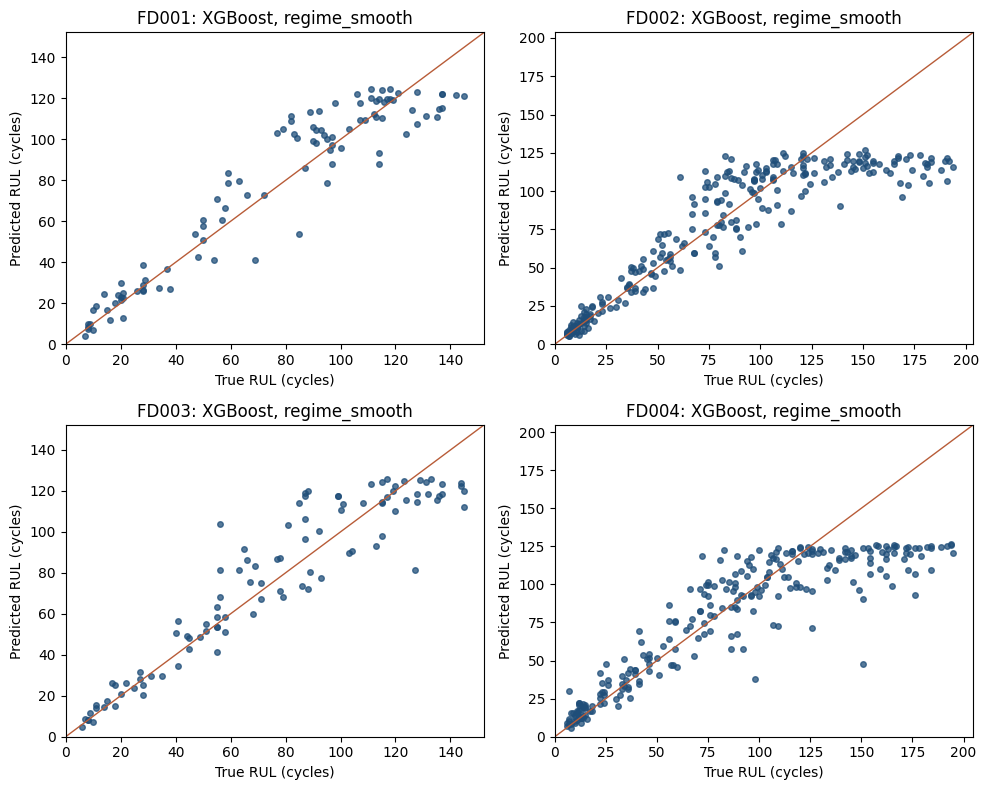

In [10]:
predictions = pd.read_csv(RESULTS / "window_feature_predictions.csv")
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=False, sharey=False)
for ax, subset in zip(axes.ravel(), w.SUBSETS):
    row = best.loc[best["subset"] == subset].iloc[0]
    part = predictions[
        (predictions["subset"] == subset)
        & (predictions["cap"] == 125)
        & (predictions["condition"] == row["condition"])
        & (predictions["model"] == row["model"])
    ]
    ax.scatter(part["y_true"], part["y_pred"], s=16, alpha=0.75, color="#1f4e79")
    upper = max(part["y_true"].max(), part["y_pred"].max()) * 1.05
    ax.plot([0, upper], [0, upper], color="#b85c38", linewidth=1)
    ax.set_title(f"{subset}: {row['model']}, {row['condition']}")
    ax.set_xlabel("True RUL (cycles)")
    ax.set_ylabel("Predicted RUL (cycles)")
    ax.set_xlim(0, upper)
    ax.set_ylim(0, upper)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "pred_vs_true_best.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. What the numbers say

On FD003, the window features reproduce the paper's Ridge and polynomial Ridge results. XGBoost lands at 13.53 RMSE on the clipped test target. The paper reports 13.36. That is a real gap of 0.18, not a match. Against the raw official labels the same XGBoost model is 14.36 RMSE.

At the baseline cap of 125, and judged by validation RMSE, the selected model is XGBoost with regime standardization and smoothing on every subset. Official test RMSE:

| Subset | Baseline | This pipeline | Change |
| --- | ---: | ---: | ---: |
| FD001 | 18.15 | 13.11 | lower |
| FD002 | 28.87 | 25.14 | lower |
| FD003 | 21.00 | 14.46 | lower |
| FD004 | 30.21 | 26.96 | lower |

FD001 and FD003 improve because the model sees 30 cycles instead of one. FD002 and FD004 improve only after regime standardization. Window features alone do not help those two subsets: XGBoost stays near 30–32 RMSE, and Ridge and polynomial Ridge produce a few enormous predictions. The NASA score then overflows. Smoothing without regime standardization does the same. After regime standardization, polynomial Ridge is stable but still behind XGBoost.

Smoothing was selected because it lowered Ridge's validation error. On FD003 it also lowers XGBoost's validation error and raises the official test error from 13.95 (window only) to 14.46. The validation rule is kept. The test set is not used to switch back.

FD001 has one operating condition, so regime standardization does not change Ridge. The small XGBoost difference there comes from the extra constant cluster column under column sampling, not from a new operating regime.


## 10. What was verified by running code, and what was assumed

**Verified by running this pipeline**

- The training and validation files share no engine ids. Test units are `1..N` and line up with the official RUL file.
- The variance rule drops the same sensors the paper drops on FD001 and FD003. Feature matrices are 70 and 75 columns.
- No FD001 or FD003 test engine is shorter than 30 cycles. Six FD002 engines and eleven FD004 engines are, and those test windows are zero-padded.
- FD003, cap 130, window only, test target clipped at 130: Ridge RMSE 17.494, MAE 14.398, R2 0.809, NASA 531.2. Polynomial Ridge RMSE 16.604, MAE 12.876, R2 0.828, NASA 631.0. These match the paper at the precision it prints.
- The same predictions scored on the raw official RUL do not match the paper (Ridge 18.50, polynomial Ridge 17.28, XGBoost 14.36).
- XGBoost on that FD003 setting is RMSE 13.53, not the paper's 13.36.
- The smoothing search selected 0.2 on every subset from validation Ridge RMSE.
- Regime standardization leaves FD001 and FD003 Ridge unchanged and is what makes the FD002 and FD004 linear models finite.
- Saved files: `results/window_feature_results.csv`, `results/window_ablation.csv`, `results/window_comparison.csv`, `results/window_feature_predictions.csv`, and `processed_data/window_features/*.npz`.

**Assumed, or not settled by this run**

- The slope formula is ordinary least squares on the cycle index. The paper does not print it. The exact FD003 linear match is the evidence that the formula agrees with theirs.
- The paper's XGBoost gap is left as a difference in the validation engines or the XGBoost version. This run did not try other splits to chase 13.36.
- The paper does not report FD002 or FD004, and it does not report the five-feature model on FD001. Those cells are blank on purpose.
- CNN and LSTM from the same paper were not trained.
